#### *Brief Background* 

For the benefit of a banking insitution, it is important mitigate the potential credit loss from borrowers. Probability of default (PD) refers to the probability that a borrower will default on their loan within a certain time period, leading to a banking insitution suffering from credit loss. A credit risk model calculating the probability of default for current borrowers will decrease the financial risk within the banking organization, as precautions or specific measures can be taken once the probability of default is too high.

#### *Problem Statement and Business Context*

The problem statement of this project is to use predict the default of probability within a 2 year time period, given competition data. This 2 year time period was used due to the competition having this time period as their frame of reference for generating this data. Treating the data as "borrowers" within a loan booking/operations system, this model can be passed over all the observations to see the current "health" or status/quality of the borrowers in the current system. Loans, credit lines, and other various products within a bank are the ways banks generate a good amount of their capital/assets, however these products also carry risk associated with the quality of the borrowers. This is why it's important to assess the probability of default for borrowers who are already within the establishment of the organization, just because they've been approved for a loan doesn't mean their credit/other variables can't change throughout the lifetime of their credit lines and/or loans.

#### *Data Description and Source*

**1. Data Description**

The data for this model was pulled from a 2011 Kaggle competition called "Give Me Some Credit" ([Kaggle Give Me Some Credit Dataset](https://www.kaggle.com/competitions/GiveMeSomeCredit)). The goal of this competition is stated as "build a model that borrowers can use to help make the best financial decisions" as well as "predicting the probability that somebody will experience financial distress in the next two years". However, there is no more information provided on the actual source of the data, such as a time period/frame or what this data is meant to represent. Each observation has various borrower information attached to is such as utilization of a credit line, the observations age, monthly income, debt ratio etc. therefore I will be treating each observation as a "borrower". The target variable (y-variable) for this model will be the SeriousDlqin2yrs, as it's a binary variable that the purpose of this competition relies on (since we want to predict whether the borrower will default within the 2 year period). 

Although there is no information regarding what this data is supposed to mimic, I will be assuming that each "borrower" has this information in a loan booking/operations system and they've already applied or have a loan. This can be inferred from the columns that are present within the data, such as observations having days past due columns meaning they've already been making or not making payments on some type of loan product. Delinquency is also traditionally something that occurs when a borrower is present within the loan booking/operations system and fails to make a payment on a loan product. Therefore, for the sake of exercise, this dataset will be thought of as "borrowers" within a loan booking/operations system in a financial insitution.

Detailed column descriptions are below along with the data type,
<br>

| Column Name | Description | Data Type |
|---|---|---|
| `SeriousDlqin2yrs` | Indicates whether the borrower experienced serious delinquency (90 days or more past due) within the following two years. `1` = Yes, `0` = No. | Binary |
| `RevolvingUtilizationOfUnsecuredLines` | The total balance on credit cards and personal lines of credit, excluding real estate and installment loans, divided by the total available credit limits. | Ratio |
| `age` | The age of the borrower in years. | Integer |
| `NumberOfTime30-59DaysPastDueNotWorse` | The number of times the borrower was 30–59 days past due, but not 60 or more days past due, during the previous two years. | Integer |
| `DebtRatio` | The borrower's monthly debt payments, alimony, and living expenses divided by monthly gross income. | Ratio |
| `MonthlyIncome` | The borrower's monthly income. | Numeric |
| `NumberOfOpenCreditLinesAndLoans` | The number of open loans and lines of credit, including installment loans such as car loans and mortgages and revolving lines of credit such as credit cards. | Integer |
| `NumberOfTimes90DaysLate` | The number of times the borrower was 90 days or more past due during the previous two years. | Integer |
| `NumberRealEstateLoansOrLines` | The number of mortgage and real estate loans, including home equity lines of credit. | Integer |
| `NumberOfTime60-89DaysPastDueNotWorse` | The number of times the borrower was 60–89 days past due, but not 90 or more days past due, during the previous two years. | Integer |
| `NumberOfDependents` | The number of dependents in the borrower's family, excluding the borrower themselves. | Integer |
**2. Data Cleaning and Transformation**

Data cleaning and transformation was performed after the split into 3 datasets: training, testing, and validation. Features that contained missing values were: MonthlyIncome and NumberOfDependents. These values were imputed using the median of the columns. One of the assumptions for a logistic regression model is the limitation of outliers or extreme values. To deal with this assumption, the data was trained and test on values within the ranges of,

$$
[Q1 - IQR*1.5, Q3 + IQR*Q3]
$$

This limits the extreme values and outliers that occur in all of the columns. 

**3. Class Imbalance**

From exploratory data analysis, it was found that from the original dataset that only ~6.68% of observations had defaulted. Since the occurence of defaults is so low, this leads to what is called class imbalances within the data which can hinder the performance of a model built on this data. For the logistic regression model that was selected, the scikit-learn logistic regression function allows for penalizing the missclassifications of the defaulting class from the observations. This allows for the model to be more sensitive to the defaulting observations. 

Another approach for class imbalance is utilizing the SMOTE re-sampling technique. This technique was used in the challenger model approach.


#### *Logistic Regression Model Details and Assumptions*

**1. Logistic Regression Model Details (all details/functions are cited from the scikit-learn documentation)**

From the scikit learn documentation, the function `LogisticRegression()` is using the following formula and cost function to derive the probability;

<br>

$$
P(y=1 | X) = \frac{1}{1+e^{(w^Tx+b)}}
$$

<br>

for $y \in \{0,1\} $, where $w^T$ are the weights of the features and $b$ is the bias/intercept term.

This function also uses the cost function below to minimize the weights and bias/intercept term,

$$
min_{w,b}(\frac{1}{2}w^Tw) + C \sum_{i=1}^{n}log(1+e^{-y_i(x_i^Tw+b)})
$$
<br>

where $C$ is the regularization parameter (default of this parameter is $1.0$). For minimizing and solving the cost function, scikit-learn uses iterative numerical optimization algorithms (the default solver is the Quasi-Newton method).

**2. Logistic Regression Assumptions**

The assumptions the follow under logistic regression ensure that a conceptual sound model is created. Assumptions are;

* Binary target variable: The dataset provided includes a column `SeriousDlqin2yrs` that is a binary variable. It denotes if an observation in the dataset has experienced delinquency within 2 years as 1, and an observation that has no experienced a delinquency in 2 years as 0. Since this is strictly binary (0/1), this column is being used as the target variable.
* Limited/No multicollinearity: Variables/features should be highly correlated with each other. After creating a correlation matrix between all of the possible features, there exists high correlation between the variables: 
    + `NumberOfTime30-59DaysPastDueNotWorse` and `NumberOfTimes90DaysLate`: correlation of 0.98
    + `NumberOfTime30-59DaysPastDueNotWorse` and `NumberOfTime60-89DaysPastDueNotWorse`: correlation of 0.99
    + `NumberOfTime60-89DaysPastDueNotWorse` and `NumberOfTimes90DaysLate`: correlation of 0.98

    These variables are highly correlated due to the fact that if an observation is 90 days late on a payment, then it would have had to been late between 30-59 days and 60-89 days. Although these features are highly correlated, they were kept within the model because each days past due late payment captures a different level of risk. For example, just keeping the 90 days late column would eliminate the predictive information from observations who were just in the 30-59 days past due or 60-89 days past due columns. 

    The correlation matrix also shows a correlation of 0.43 between the features of `NumberOfOpenCreditLinesAndLoans` and `NumberRealEstateLoansOrLines`. These two features were included in the model despite having a notable correlation because they show two different financial obligation of an observation in this dataset.
* Reduced outliers or extreme values: Boxplots of the features reveal that several of the features have extreme values. To tackle this issue, the model is trained on feature data that falls within the range of,

$$
[Q1 - IQR*1.5, Q3 + IQR*Q3]
$$

* Linearity of log-odds: To determine the linearity of features, the Box-Tidwell test was performed. The Box-Tidwell test adds interacting terms between the continous features and the log of the features ($X*log(X)$) into a regression model to determine p-values. P-values are then used for interpretation following the structure of: linearity assumption is met (p-value greater than 0.05) and linearity violated (p-value less than 0.05). For the features in this dataset, it was found that only three features has not violated linearity, while the rest of the features had violated linearity. Despite this, I kept all of the features in the model due to them being important factors into determining an observations probability of default. A way to handle the featuers that had violated linearity is by adding another term to create polynomials within the model, which is an on-going process.
* Independence of observations: Observations within the dataset must be independent. This dataset did not include documentation to report on if the observations are independent, therefore it is assumed that they are all independent.

**3. Feature Selection for Logistic Regression**

The feature selection and justification for each feature selection is below;
+ `RevolvingUtilizationOfUnsecuredLines`: shows how much an observation is using of their unsecured line/credit, meaning if they have a higher value of this ratio they are using more of the credit. A high utilization ratio can indicate that an observation is relying heavily on the credit line and potentially have low financial stability/flexbility. From this we can infer that an observation may default if they have a higher utilization ratio. From exploratory data analysis, the average utilization for observations that defaulted was actually lower. 
+ `NumberOfTime30-59DaysPastDueNotWorse`: an observation was 30-59 days past due on a payment. If an observation has accumulated a lot of these days past dues, they could've defaulted. From EDA, the average 30-59 days past due is higher for observations that defaulted.
+ `DebtRatio`: the debt to income ratio of an observation. A higher debt ratio indicates that an observation has a lot of debt to take on, meaning they might not have the funds to cover the payments for a credit line/loan. From EDA, shows that there was a lower average of debt ratio for observations that defaulted. An important note on this, since it's contradictory, this feature had very dramatic extreme values, which leads to such a high average value from the EDA. 
+ `MonthlyIncome`: is a good measure of seeing if an observation can repay/stick to their payment plan for credit lines/loans. From EDA, the average monthly income was lower for observations that defaulted.
+ `NumberOfTimes90DaysLate`: an observation was 90 days past due on a payment. If an observation has accumulated a lot of these days past dues, they could've defaulted. From EDA, the average 30-59 days past due is higher for observations that defaulted.
+ `NumberOfTime60-89DaysPastDueNotWorse`: an observation was 60-89 days past due on a payment. If an observation has accumulated a lot of these days past dues, they could've defaulted. From EDA, the average 30-59 days past due is higher for observations that defaulted.
+ `age`: feature was included due to an average of younger observations defaulted compared to older. 
+ `NumberOfOpenCreditLinesAndLoans`: shows how many current open credit lines and loans exist for an observation. From EDA, there was a lower average of open credit lines and loans for observations that defaulted.
+ `NumberOfDependents`: show how many dependents an observation has. From EDA, there was a higher average of dependents for an observation that defaulted.
+ `NumberRealEstateLoansOrLines`: shows how many current real estate loans or lines exist for an observation. From EDA, there was a lower average of real estate loans or liens for observations that defaulted.

Exploratory data analysis (EDA) for all of these features was completed before the data was split and cleaned.

**4. Consideration of Other Models**

Logistic regression was selected for this model due to: model transparency/clarity, documentation simplicity, and reproducibility. The logistic regression model has several articles of documentation on the mathematical concepts behind the model giving it more clarity. Selecting features for this type of model is more straightword or transparent, as you can directly interpret the coefficients produced by the model. Documenting this model is also more simplistic, as the assumptions that hold under this model are easy to code/find. Finally, this model can be reproduced efficiently, allowing the developer to add specific details or terms into/out of the model. On top of this, the logistic regression (due to the nature of the binary variable) gives a probability which can be interpreted easily for the sake of finding the probability of default. 

Despite selecting a logistic regression model, SMOTE was also used as challenger approach to the models development to help with class imbalances.

**5. Challenger Model**

Since the logistic regression model offers reproducibility another model was built for a challenger approach. Since this data has class imbalance (due to the small amount of delinquencies in the dataset), for the challenger model, the SMOTE approach was used. SMOTE resamples the data to have a matching amount of delinquencies with nondelinquencies. This challenger was run and compared with the original logistic regression model that had no resampling. It was found that there wasn't a drastic difference to select the model with the re-sampling as a better model. 

#### *Model Limitations*

1. **The choices of limiting/restricting with outliers are within the data**: this limitation occurs when attempting to satisfy an assumption of logistic regression, however some outliers within the data might be key sign of delinquency within 2 years. The restriction on the outliers and removing them for ALL columns is a hefty penalty, which could leave out some of those "important" outliers that could influence the model to make better decisions.
2. **Including highly correlated features**: once again, to satisfy the assumptions of logistic regression there must be no/little multicollinearity. However three features, despite being highly correlated, were included within the training data of the model. This could cause issues with the model properly distinguishing the difference between the three features, leading to "worse" decisions being made by the model.
3. **Including features that "fail linearity"**: another assumption of logistic regression is checking the linearity of the features with the log-odds of the target variable, but most of the features included within the model fail this assumption. This is probably one of the most important drawbacks from this model, which could lead to it's decreased performance. More is spoken about this issue within the ongoing monitoring/improvements section within the documentation.
4. **Data cleaning performance**: every time new data is passed through this model, it must be cleaned in the exact same way as the training data. This could lead to limitations with depending on having consitent data cleaning performance each time new data is wanting to be passed through this model as the data cleaning steps must be the exact same from the training of the model.
5. **Population change**: with new data being passed into the model, the population statistics (such as having more left-leaning/right-leaning distributions) could change over time depending on economic or characteristic changes. This leads to a limitation in the quality of predictions from the model.

#### *Model Implementation*

1. **Data cleaning and scaling**

Utilizing the validation data set, impute missing values with median as well as restrict the outliers using the range of,
$$
[Q1 - IQR*1.5, Q3 + IQR*Q3]
$$

After imputing median and restricting outliers, scale the data using the standardization method.
<br>

2. **Prediction**

Pass the data through the model by called the `my_model` function.

3. **Prediction Table**

Pass the predictions data into the table function to get back the prediction table.


#### *Ongoing Monitoring and Improvements*

1. **ROC-AUC and Precision-Recall Analysis**: when new data is being passed through the model, make sure to check if the model is still performing correctly. By doing ROC-AUC analysis, it can show if the model can still distinguish the difference between defaulters and non-defaulters over an entire threshold of values that determine what a defaulter is. For precision-recall analysis, it shows the probability of predicted values that were correctly identified as a defaulter. These tests make sure that the model is still performing correctly as the data changes.
2. **Monitor Population Changes**: due to economic or characteristic qualities changing within data, it could change the probabilities predicted by the model.
3. **Implementation Checks**: making sure that the data being passed through the model is being cleaned with the correct range of data and imputing the medians.
4. **Updating/Improving the Model**: to "fix" the issue involving including features that fail linearity, adding polynomial terms is an ongoing project for this model to improve model precision and recall.

In [27]:
# MODEL CODE BELOW!

# loading in various packages
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plot
import statsmodels.api as sm
import joblib
import sklearn

# reading in the dataset, 
data=pd.read_csv("cs-training.csv.zip") #data should be in the same file as this notebook

In [28]:
# looking at the delinquency of the entire population
nondelq_count=(data["SeriousDlqin2yrs"]==0).sum()
delq_count=(data["SeriousDlqin2yrs"]==1).sum()

total_delq=(delq_count/(nondelq_count+delq_count))*100
print(f"total delinq. accounts in 2 years was {total_delq}")

# looking at the relationship between the possible features and the target variable
np.transpose(data.groupby("SeriousDlqin2yrs").mean())

total delinq. accounts in 2 years was 6.683999999999999


SeriousDlqin2yrs,0,1
Unnamed: 0,74968.042429,75453.643427
RevolvingUtilizationOfUnsecuredLines,6.168855,4.367282
age,52.751375,45.926591
NumberOfTime30-59DaysPastDueNotWorse,0.280109,2.388490
DebtRatio,357.151168,295.121066
MonthlyIncome,6747.837774,5630.826493
NumberOfOpenCreditLinesAndLoans,8.493620,7.882306
NumberOfTimes90DaysLate,0.135225,2.091362
NumberRealEstateLoansOrLines,1.020368,0.988530
NumberOfTime60-89DaysPastDueNotWorse,0.126666,1.828047


In [29]:
y = data["SeriousDlqin2yrs"] # defining the target variable
x = data[["MonthlyIncome","DebtRatio","NumberOfTimes90DaysLate","RevolvingUtilizationOfUnsecuredLines","NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse","NumberOfDependents","NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines","age"]] # defining the features

# loading in the splitting, scalar, and regression function
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# splitting the data into: 80% training, 10% testing, 10% validation

# splitting into 90, 10
x_temp, x_test, y_temp, y_test = train_test_split(
    x, y,
    test_size=0.10,
    random_state=42,
    stratify=y
)

# splitting the 90 into 80, 10
x_train, x_val, y_train, y_val = train_test_split(
    x_temp, y_temp,
    test_size=1/9,
    random_state=42,
    stratify=y_temp
)

/Users/annakpope/Library/Python/3.9/lib/python/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/annakpope/Library/Python/3.9/lib/python/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/annakpope/Library/Python/3.9/lib/python/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/annakpope/Library/Python/3.9/lib/python/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/annakpope/Library/Python/3.9/lib/python/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/annakpope/Library/Pytho

Optimization terminated successfully.
         Current function value: 0.192770
         Iterations 9
                                feature       p-value  \
0                         MonthlyIncome  2.419289e-01   
1                             DebtRatio  1.046266e-02   
2               NumberOfTimes90DaysLate  6.377829e-96   
3  RevolvingUtilizationOfUnsecuredLines  5.022236e-02   
4  NumberOfTime30-59DaysPastDueNotWorse  4.584384e-58   
5  NumberOfTime60-89DaysPastDueNotWorse  7.261112e-03   
6                    NumberOfDependents  3.257924e-01   
7       NumberOfOpenCreditLinesAndLoans  2.634405e-48   
8          NumberRealEstateLoansOrLines  4.920717e-07   
9                                   age  3.092365e-05   

                            interpretation  
0  No significant evidence of nonlinearity  
1         Potential violation of linearity  
2         Potential violation of linearity  
3  No significant evidence of nonlinearity  
4         Potential violation of linearity  


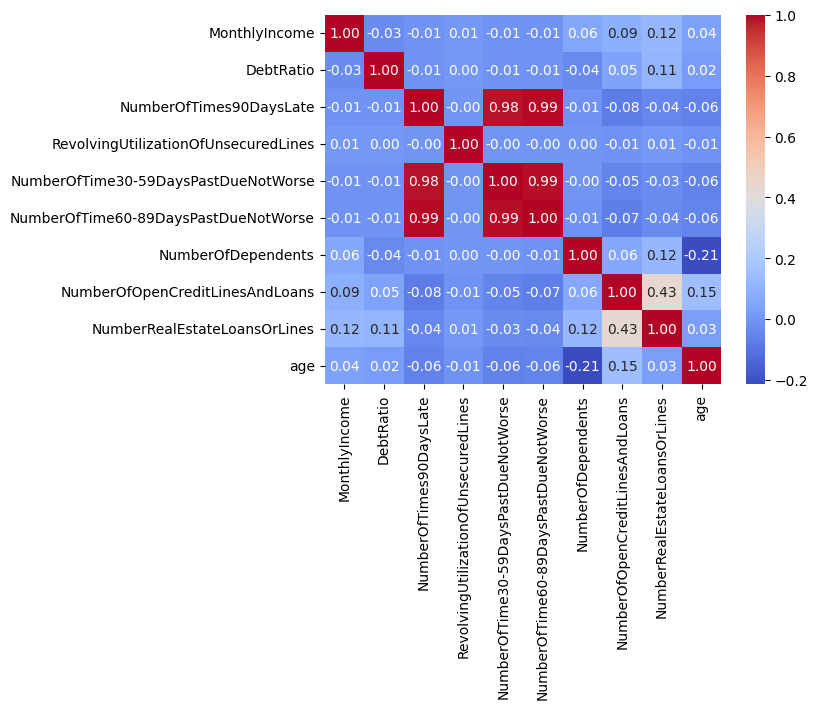

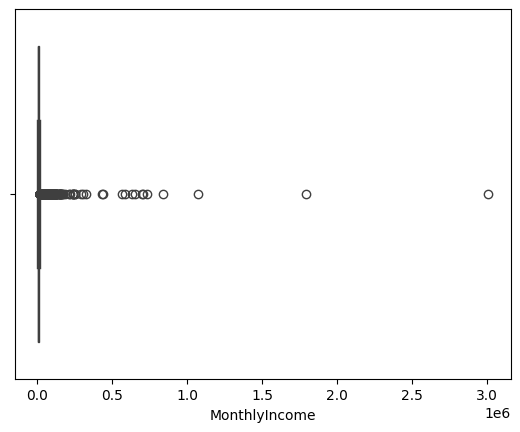

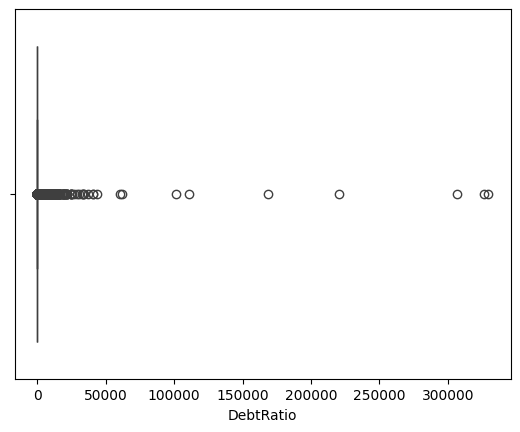

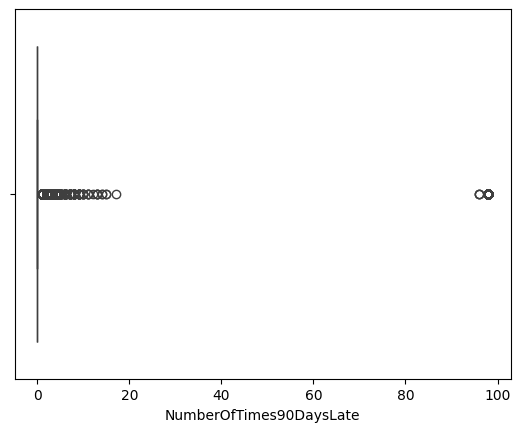

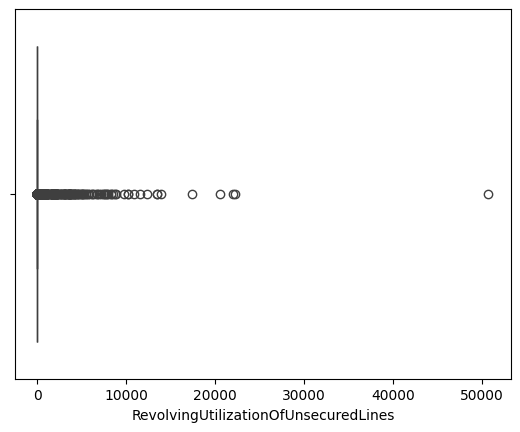

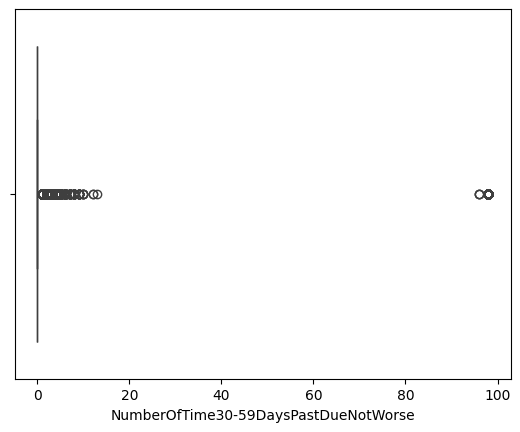

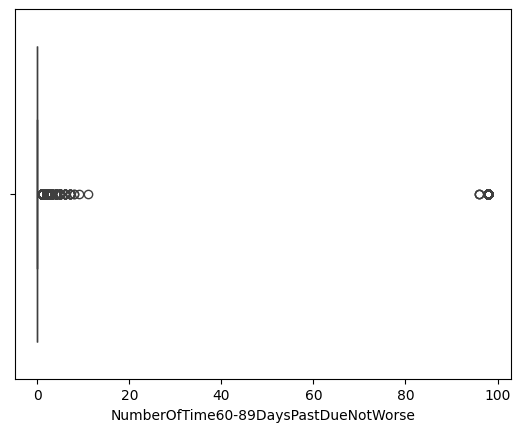

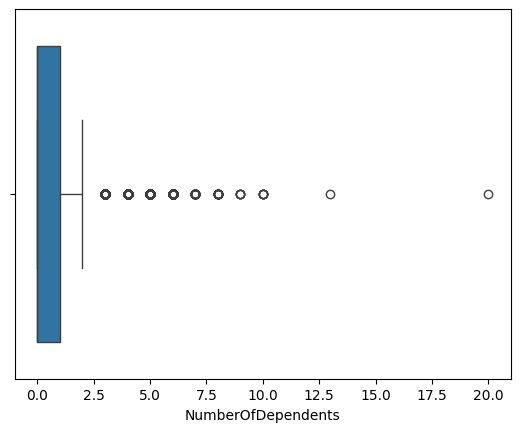

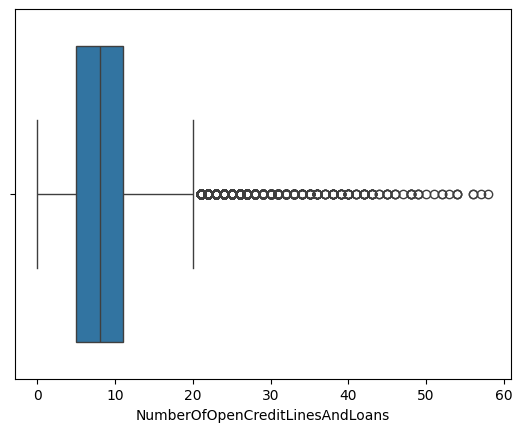

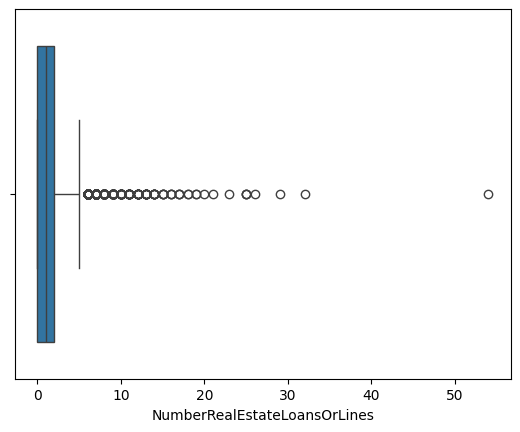

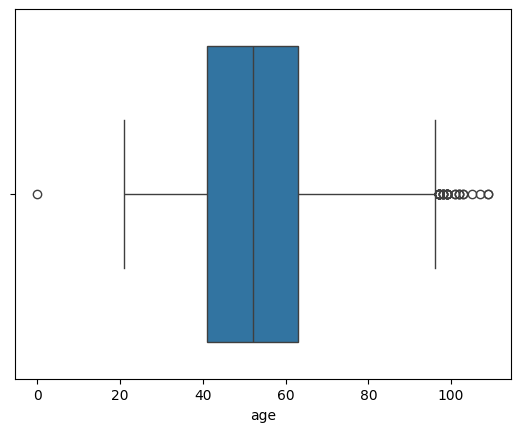

In [30]:
# checking the assumptions for logistic regression

# 1. linearity of log odds

# saving the continous features
continuous_rv = ["MonthlyIncome","DebtRatio","NumberOfTimes90DaysLate","RevolvingUtilizationOfUnsecuredLines","NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse","NumberOfDependents","NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines","age"]

x_tidwell_test = x_train[continuous_rv].copy() # saving a copy of the dataset
# adding x*log(x) to all the terms
for col in continuous_rv:
    x_tidwell_test[f"{col}_log"]=x_tidwell_test[col]*np.log(x_tidwell_test[col]) # some zeros in columns -> NaN values in the log columns

x_tidwell_test = sm.add_constant(x_tidwell_test) # adding intercept
x_tidwell_test.head(10)

# imputing NaN values w/ the median of columns
for col in x_tidwell_test:
    x_tidwell_test[col]=x_tidwell_test[col].fillna(x_tidwell_test[col].median())

# fitting the tidwell testing data using the y_train and x_train data
tidwell_test = sm.Logit(y_train,x_tidwell_test).fit()

# print(tidwell_test.pvalues[[f"{col}_log" for col in continuous_rv]])
# printing the test w/ formatting to describe the p-values
p_values = tidwell_test.pvalues[tidwell_test.pvalues.index.str.endswith("_log")]
p_values = pd.to_numeric(p_values, errors="coerce") # converting the numeric
# saving the results in a new dataframe
tidwell_results = pd.DataFrame({
    "feature":p_values.index.str.replace("_log", "", regex=False),
    "p-value":p_values.values
})

# creating a function for understand the p-values
def interpret(p):
    if p < 0.05:
        return "Potential violation of linearity"
    else:
        return "No significant evidence of nonlinearity"

tidwell_results["interpretation"] = (tidwell_results["p-value"].apply(interpret))
print(tidwell_results)

# 2. checking multicollinearity

corr_matrix = x_train.corr() # creating a correlation matrix
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f") # creating the heatmap
plot.show() # got some strong correlation between the number of days late columns

# 3. checking outliers
for col in x_train:
    sns.boxplot(x=x_train[col])
    plot.show() # from this boxplot, there are clear outliers is all of the columns -> going to use the IQR +- 1.5 rule

In [31]:
# data cleaning AFTER the split

# imputing the missing MonthlyIncome and NumberOfDependents data w/ the median of the columns
median_income = x_train["MonthlyIncome"].median()
median_depend = x_train["NumberOfDependents"].median()

x_train["MonthlyIncome"]=x_train["MonthlyIncome"].fillna(median_income)
x_train["NumberOfDependents"]=x_train["NumberOfDependents"].fillna(median_depend)

# clipping ALL of the columns to deal with the outliers detected from EDA
for col in x_train:
    q1 = x_train[col].quantile(0.25)
    q3 = x_train[col].quantile(0.75)
    iqr = q3-q1

    lower=q1 - iqr*1.5
    upper=q3 + iqr*1.5

    x_train[col]=x_train[col].clip(lower=lower,upper=upper)

# for col in x_train:
#     sns.boxplot(x=x_train[col])
#     plot.show() # the clipping worked

In [32]:
# scaling the training and testing data sets
scaling = StandardScaler()
x_train_scaled=scaling.fit_transform(x_train)

# cleaning the testing data

# imputing any columns that have missing data with the median of the column
for col in x_test:
    x_test[col]=x_test[col].fillna(x_test[col].median())

# clipping all of the columns to deal
for col in x_test:
    q1 = x_test[col].quantile(0.25)
    q3 = x_test[col].quantile(0.75)
    iqr = q3-q1

    lower=q1 - iqr*1.5
    upper=q3 + iqr*1.5

    x_test[col]=x_test[col].clip(lower=lower,upper=upper)

x_test_scaled=scaling.transform(x_test)

In [33]:
# creating the logistic regression model: adjusting for class imbalances
my_model=LogisticRegression(class_weight="balanced") # using the class_weight=balanced to deal w/ class imbalance (attempting to penalize delq. more)
my_model.fit(x_train_scaled,y_train) # fitting the model using the training data

LogisticRegression(class_weight='balanced')

In [34]:
# using the testing dataset to predict probability of defaults
pd_predictions=my_model.predict_proba(x_test_scaled)[:,1]

# creating a probability table that includes all the feature information
pd_table_og=x_test.copy()
pd_table_og.insert(0,'Borrower',np.arange(1, len(pd_predictions)+1))

# adding probability to the table as well as the original default
pd_table_og['PD (%)']=pd_predictions*100
pd_table_og['Actual Default']=y_test

# printing the table
pd_table_og.head()

,Borrower,MonthlyIncome,DebtRatio,NumberOfTimes90DaysLate,RevolvingUtilizationOfUnsecuredLines,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfOpenCreditLinesAndLoans,NumberRealEstateLoansOrLines,age,PD (%),Actual Default
108706,1,5486.5,1.950601,0,0.559594,0,0,0.0,2,0,45,45.464337,0
36294,2,2232.0,0.838334,0,0.859627,0,0,1.0,6,1,55,73.753872,0
32214,3,5486.5,1.950601,0,0.004457,0,0,0.0,10,1,49,20.600746,0
28651,4,5486.5,1.950601,0,1.000000,0,0,0.0,3,0,69,65.558069,0
25291,5,12750.0,0.232389,0,0.513690,0,0,1.0,20,1,66,46.214529,0


In [35]:
# challenger model creation
# SMOTE challenger model

#importing the SMOTE package
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42) #saving the function
x_train_resampled, y_train_resampled = smote.fit_resample(
    x_train_scaled,
    y_train
) # resampling the data to even out the class imbalances

my_model_edition2 = LogisticRegression()

my_model_edition2.fit(x_train_resampled, y_train_resampled) # fitting the resampled data using logistic regression

# predicting probabilities using the test data set (SMOTE re-sampled)
pd_predictions_SMOTE=my_model_edition2.predict_proba(x_test_scaled)[:,1]

# creating the prediction table for the SMOTE re-sampled data
pd_table_SMOTE=x_test.copy()
pd_table_SMOTE.insert(0,'Borrower',np.arange(1, len(pd_predictions_SMOTE)+1))

# adding probability to the table as well as the original default
pd_table_SMOTE['PD (%)']=pd_predictions_SMOTE*100
pd_table_SMOTE['Actual Default']=y_test

# printing
pd_table_SMOTE.head()

/Users/annakpope/Library/Python/3.9/lib/python/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


,Borrower,MonthlyIncome,DebtRatio,NumberOfTimes90DaysLate,RevolvingUtilizationOfUnsecuredLines,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfOpenCreditLinesAndLoans,NumberRealEstateLoansOrLines,age,PD (%),Actual Default
108706,1,5486.5,1.950601,0,0.559594,0,0,0.0,2,0,45,45.273134,0
36294,2,2232.0,0.838334,0,0.859627,0,0,1.0,6,1,55,73.727093,0
32214,3,5486.5,1.950601,0,0.004457,0,0,0.0,10,1,49,20.252278,0
28651,4,5486.5,1.950601,0,1.000000,0,0,0.0,3,0,69,64.998188,0
25291,5,12750.0,0.232389,0,0.513690,0,0,1.0,20,1,66,45.439469,0


In [36]:
# comparing the average probability of default for each of the models
print("Original Average PD:", pd_predictions.mean() * 100)
print("SMOTE Average PD:", pd_predictions_SMOTE.mean() * 100)

Original Average PD: 38.60101775590754
SMOTE Average PD: 38.36614241799647


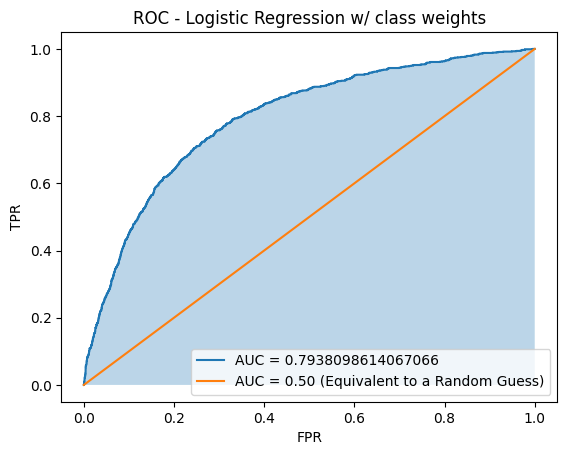

In [37]:
# ROC-AUC curve analysis for both the logistic regression and SMOTE re-sampled logistic regression models 

#loading in the packages
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import precision_recall_curve

#calculating the auc
auc = roc_auc_score(y_test, pd_predictions)

# finding the false positive rate and true positive rate over all the thresholds
fpr, tpr, thresholds = roc_curve(
    y_test,
    pd_predictions
)

# plotting
plot.plot(fpr, tpr, label=f"AUC = {auc}")
plot.fill_between(fpr, tpr, alpha=0.3)
plot.xlabel("FPR")
plot.ylabel("TPR")
plot.plot([0,1],[0,1], label="AUC = 0.50 (Equivalent to a Random Guess)")
plot.legend(loc=4)
plot.title("ROC - Logistic Regression w/ class weights")
plot.show()

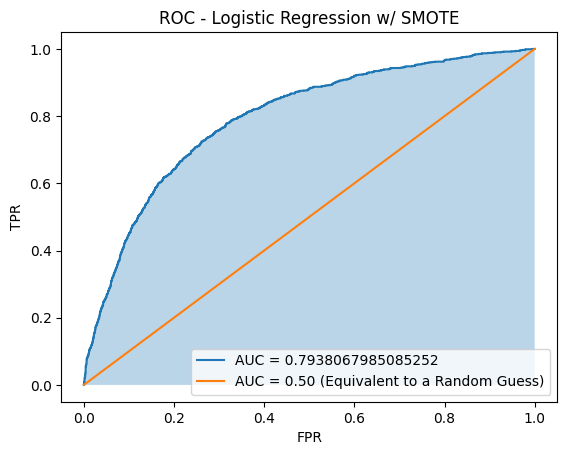

In [38]:
# same code from above but using the SMOTE DATA

auc = roc_auc_score(y_test, pd_predictions_SMOTE)

fpr, tpr, thresholds = roc_curve(
    y_test,
    pd_predictions_SMOTE
)

plot.plot(fpr, tpr, label=f"AUC = {auc}")
plot.fill_between(fpr, tpr, alpha=0.3)
plot.xlabel("FPR")
plot.ylabel("TPR")
plot.plot([0,1],[0,1], label="AUC = 0.50 (Equivalent to a Random Guess)")
plot.legend(loc=4)
plot.title("ROC - Logistic Regression w/ SMOTE")
plot.show()

In [41]:
# model implementation

# data cleaning

validation_set = x_val

for col in validation_set:
    validation_set[col]=validation_set[col].fillna(x_test[col].median())

# clipping all of the columns to deal
for col in validation_set:
    q1 = validation_set[col].quantile(0.25)
    q3 = validation_set[col].quantile(0.75)
    iqr = q3-q1

    lower=q1 - iqr*1.5
    upper=q3 + iqr*1.5

    validation_set[col]=validation_set[col].clip(lower=lower,upper=upper)

# scaling
x_val_scaled = scaling.transform(validation_set)

# predicting
val_predictions = my_model.predict_proba(x_val_scaled)[:,1]

# recreating the table from above
pd_table=x_test.copy()
pd_table.insert(0,'Borrower',np.arange(1, len(val_predictions )+1))

# adding probability to the table as well as the original default
pd_table['PD (%)']=val_predictions*100
pd_table['Actual Default']=y_test
pd_table.head()



,Borrower,MonthlyIncome,DebtRatio,NumberOfTimes90DaysLate,RevolvingUtilizationOfUnsecuredLines,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfOpenCreditLinesAndLoans,NumberRealEstateLoansOrLines,age,PD (%),Actual Default
108706,1,5486.5,1.950601,0,0.559594,0,0,0.0,2,0,45,31.900426,0
36294,2,2232.0,0.838334,0,0.859627,0,0,1.0,6,1,55,13.219616,0
32214,3,5486.5,1.950601,0,0.004457,0,0,0.0,10,1,49,18.622605,0
28651,4,5486.5,1.950601,0,1.000000,0,0,0.0,3,0,69,32.800608,0
25291,5,12750.0,0.232389,0,0.513690,0,0,1.0,20,1,66,11.159564,0
